In [1]:

# Step 1: Check the working environment

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import random

# Check Python and PyTorch versions
import sys

print("Python Version:", sys.version)
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)

# Check GPU availability
if torch.cuda.is_available():
    print("\nGPU is available!")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("\nGPU is not available. We will use CPU.")

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected Device:", device)


Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130

GPU is available!
GPU Name: Tesla T4
Selected Device: cuda


In [2]:

# Step 2: Download the Intel Image Classification dataset

import os
import zipfile
import urllib.request

dataset_url = "https://www.kaggle.com/api/v1/datasets/download/puneet6060/intel-image-classification"

zip_path = "/content/intel-image-classification.zip"
extract_path = "/content/intel_dataset"

if not os.path.exists(extract_path):
    print("Downloading dataset...")

    urllib.request.urlretrieve(dataset_url, zip_path)

    print("Download completed!")
    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Extraction completed!")

else:
    print("Dataset already exists!")

print("\nDataset location:", extract_path)
print("Available files:", os.listdir(extract_path))


Download completed!
Extracting dataset...
Extraction completed!

Dataset location: /content/intel_dataset
Available files: ['seg_pred', 'seg_train', 'seg_test']


In [3]:

# Step 3: Locate training and testing folders

for root, dirs, files in os.walk(extract_path):

    if "seg_train" in dirs:
        train_dir = os.path.join(root, "seg_train")

    if "seg_test" in dirs:
        test_dir = os.path.join(root, "seg_test")

print("Training directory:", train_dir)
print("Testing directory:", test_dir)

print("\nTraining classes:")
print(os.listdir(train_dir))

print("\nTesting classes:")
print(os.listdir(test_dir))


Training directory: /content/intel_dataset/seg_train/seg_train
Testing directory: /content/intel_dataset/seg_test/seg_test

Training classes:
['glacier', 'street', 'forest', 'buildings', 'sea', 'mountain']

Testing classes:
['glacier', 'street', 'forest', 'buildings', 'sea', 'mountain']


In [4]:

# Step 4: Count images in each class

from collections import Counter

classes = sorted(os.listdir(train_dir))

train_counts = {}
test_counts = {}

for class_name in classes:

    train_class_path = os.path.join(train_dir, class_name)
    test_class_path = os.path.join(test_dir, class_name)

    train_counts[class_name] = len(os.listdir(train_class_path))
    test_counts[class_name] = len(os.listdir(test_class_path))

print("Training Image Count:")
for class_name, count in train_counts.items():
    print(f"{class_name}: {count}")

print("\nTesting Image Count:")
for class_name, count in test_counts.items():
    print(f"{class_name}: {count}")

print("\nTotal Training Images:", sum(train_counts.values()))
print("Total Testing Images:", sum(test_counts.values()))


Training Image Count:
buildings: 2191
forest: 2271
glacier: 2404
mountain: 2512
sea: 2274
street: 2382

Testing Image Count:
buildings: 437
forest: 474
glacier: 553
mountain: 525
sea: 510
street: 501

Total Training Images: 14034
Total Testing Images: 3000


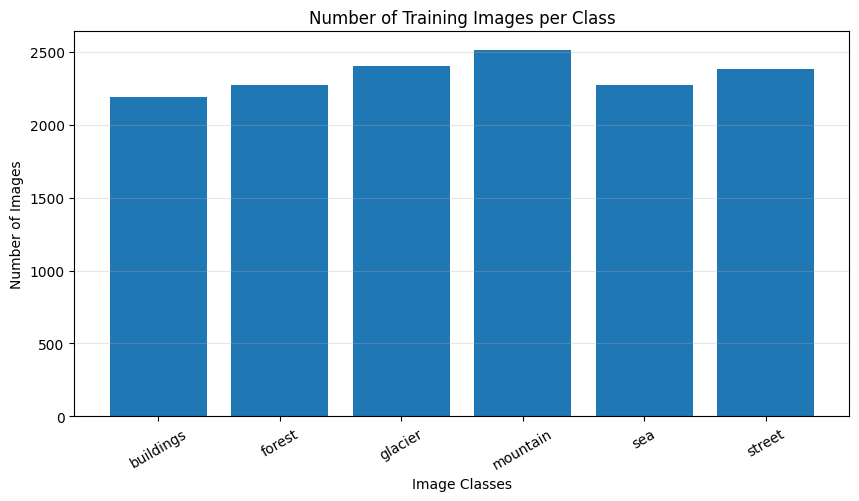

In [5]:

# Step 5: Visualize dataset distribution

plt.figure(figsize=(10, 5))

plt.bar(train_counts.keys(), train_counts.values())

plt.title("Number of Training Images per Class")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.show()


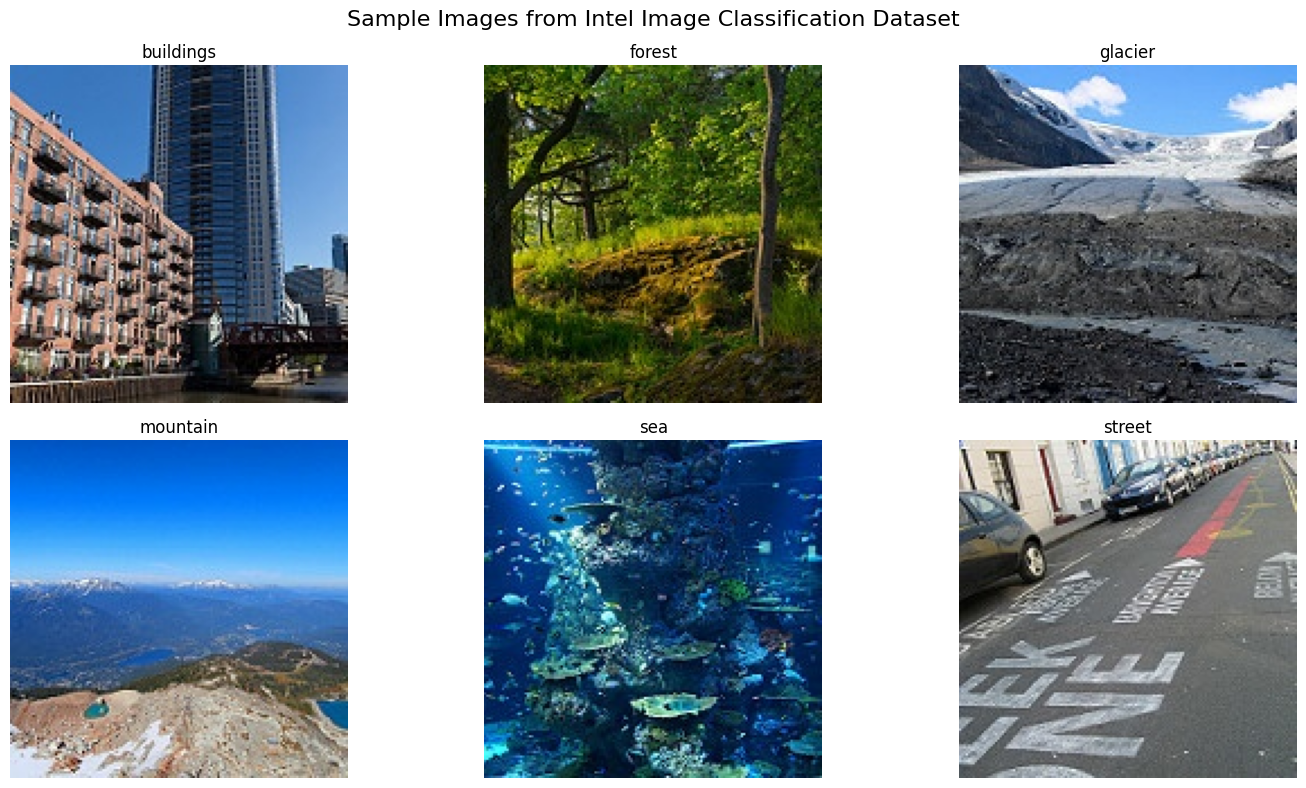

In [6]:

# Step 6: Display sample images from each class

from PIL import Image

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(classes):

    class_path = os.path.join(train_dir, class_name)

    # Select one image from the class
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    # Open image
    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.suptitle("Sample Images from Intel Image Classification Dataset",
             fontsize=16)

plt.tight_layout()
plt.show()


In [7]:

# Step 7: Check original image dimensions

image_sizes = []

for class_name in classes:

    class_path = os.path.join(train_dir, class_name)

    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    image_sizes.append(img.size)

    print(f"{class_name}: {img.size}")

print("\nImage dimensions checked successfully.")


buildings: (150, 150)
forest: (150, 150)
glacier: (150, 150)
mountain: (150, 150)
sea: (150, 150)
street: (150, 150)

Image dimensions checked successfully.


In [8]:

# Step 8: Import preprocessing libraries

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torch

print("Preprocessing libraries imported successfully!")


Preprocessing libraries imported successfully!


In [9]:

# Step 9: Define image transformations

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Validation and testing transformations
test_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("Image transformations defined successfully!")


Image transformations defined successfully!


In [10]:

# Step 10: Load the image datasets

from torchvision.datasets import ImageFolder
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split

# Load training images with training transformations
full_train_dataset = ImageFolder(
    root=train_dir,
    transform=train_transform
)

# Load the same images with validation transformations
full_val_dataset = ImageFolder(
    root=train_dir,
    transform=test_transform
)

# Get labels for stratified splitting
labels = full_train_dataset.targets

# Generate training and validation indices
train_indices, val_indices = train_test_split(
    range(len(labels)),
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Create training and validation subsets
train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_val_dataset, val_indices)

# Load separate testing dataset
test_dataset = ImageFolder(
    root=test_dir,
    transform=test_transform
)

# Display dataset information
class_names = full_train_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

print("\nTraining images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))


Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6

Training images: 11227
Validation images: 2807
Testing images: 3000


In [11]:

# Step 11: Create DataLoaders

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


DataLoaders created successfully!

Training batches: 351
Validation batches: 88
Testing batches: 94


In [12]:

# Step 12: Inspect one training batch

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image data type:", images.dtype)
print("Image device before transfer:", images.device)

# Move images to GPU
images = images.to(device)
labels = labels.to(device)

print("\nImage device after transfer:", images.device)
print("Label device after transfer:", labels.device)


Image batch shape: torch.Size([32, 3, 150, 150])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Image device before transfer: cpu

Image device after transfer: cuda:0
Label device after transfer: cuda:0


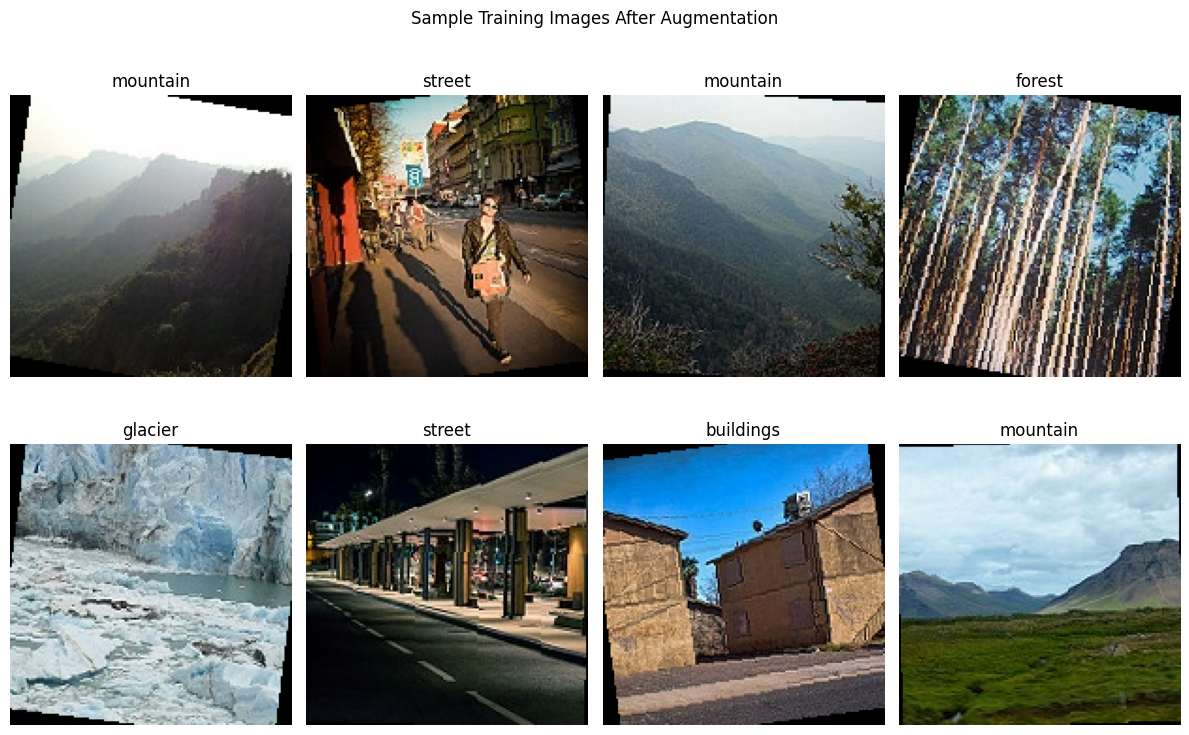

In [13]:

# Step 13: Display sample training images

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(8):

    # Reverse normalization
    img = images[i].permute(1, 2, 0)
    img = img * 0.5 + 0.5

    plt.subplot(2, 4, i + 1)
    plt.imshow(img.clamp(0, 1))

    class_index = labels[i].item()
    plt.title(class_names[class_index])
    plt.axis("off")

plt.suptitle("Sample Training Images After Augmentation")
plt.tight_layout()
plt.show()


### Data Preprocessing and Augmentation

The images were loaded using PyTorch's ImageFolder function. All images were resized to 150 × 150 pixels and converted into tensors.

Normalization was applied to scale the pixel values into the range of approximately -1 to 1. For data augmentation, random horizontal flipping and random rotation were applied to the training images.

The original training dataset was divided into 80% training data and 20% validation data using stratified splitting. The separate test dataset was kept unchanged for final evaluation.

Finally, DataLoaders were created with a batch size of 32 to process the images efficiently during model training.

## 4. Define CNN Architecture

In this section, a custom Convolutional Neural Network is designed
using PyTorch. The model contains three convolutional blocks,
followed by fully connected layers for classifying six image categories.

In [14]:

# Step 14: Define Custom CNN Architecture

import torch
import torch.nn as nn

class CustomCNN(nn.Module):

    def __init__(self, num_classes=6):
        super(CustomCNN, self).__init__()

        # First Convolution Block
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Second Convolution Block
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Third Convolution Block
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Flatten Layer
        self.flatten = nn.Flatten()

        # Fully Connected Layers
        self.fc = nn.Sequential(
            nn.Linear(128 * 18 * 18, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)

        x = self.flatten(x)

        x = self.fc(x)

        return x


# Create the model
model = CustomCNN(num_classes=num_classes)

# Move model to GPU
model = model.to(device)

print(model)


CustomCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Sequential(
    (0): Linear(in_features=41472, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=256, out_features=6, bias=True)
  )
)


In [15]:

# Step 15: Generate CNN Model Summary

!pip install -q torchinfo

from torchinfo import summary

summary(
    model,
    input_size=(1, 3, 150, 150),
    device=str(device)
)


Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 6]                    --
├─Sequential: 1-1                        [1, 32, 75, 75]           --
│    └─Conv2d: 2-1                       [1, 32, 150, 150]         896
│    └─ReLU: 2-2                         [1, 32, 150, 150]         --
│    └─MaxPool2d: 2-3                    [1, 32, 75, 75]           --
├─Sequential: 1-2                        [1, 64, 37, 37]           --
│    └─Conv2d: 2-4                       [1, 64, 75, 75]           18,496
│    └─ReLU: 2-5                         [1, 64, 75, 75]           --
│    └─MaxPool2d: 2-6                    [1, 64, 37, 37]           --
├─Sequential: 1-3                        [1, 128, 18, 18]          --
│    └─Conv2d: 2-7                       [1, 128, 37, 37]          73,856
│    └─ReLU: 2-8                         [1, 128, 37, 37]          --
│    └─MaxPool2d: 2-9                    [1, 128, 18, 18]          --
├─Flat

### CNN Architecture Description

The custom CNN consists of three convolutional blocks. The first block contains 32 filters, the second contains 64 filters, and the third contains 128 filters. Each block uses a 3 × 3 convolution, ReLU activation, and 2 × 2 max pooling.

After feature extraction, the output is flattened and passed through a fully connected layer containing 256 neurons. ReLU activation and dropout with a rate of 0.5 are used to help reduce overfitting.

Finally, the output layer contains six neurons, representing the six image categories. The model uses a custom architecture and is implemented using PyTorch.

## 5. Training and Optimization

The CNN model is trained using the Adam optimizer and Cross Entropy Loss.
The learning rate is set to 0.001. Training and validation performance
are monitored after each epoch.

In [16]:

# Step 16: Define loss function and optimizer

import torch.optim as optim

# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training configuration
EPOCHS = 15
LEARNING_RATE = 0.001

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)


Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epochs: 15
Learning Rate: 0.001


In [17]:

# Step 17: Define training and validation functions

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Get predicted classes
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions created successfully!")


Training and validation functions created successfully!


In [18]:

# Step 18: Train the CNN model

# Store training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Early stopping configuration
best_val_loss = float("inf")
patience = 4
epochs_without_improvement = 0

# Model save path
best_model_path = "/content/best_cnn_model.pth"

print("Starting CNN Training...\n")

for epoch in range(EPOCHS):

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Validation
    val_loss, val_accuracy = validate_one_epoch(
        model, val_loader, criterion, device
    )

    # Store results
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Display epoch results
    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")
    print("-" * 40)

    # Save the best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), best_model_path)

        print("Best model saved!")

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:

        print("\nEarly stopping triggered!")
        break

print("\nTraining completed!")
print("Best Validation Loss:", round(best_val_loss, 4))


Starting CNN Training...

Epoch [1/15]
Training Loss: 1.0396
Training Accuracy: 59.54%
Validation Loss: 0.7816
Validation Accuracy: 69.75%
----------------------------------------
Best model saved!
Epoch [2/15]
Training Loss: 0.7464
Training Accuracy: 72.55%
Validation Loss: 0.6741
Validation Accuracy: 75.81%
----------------------------------------
Best model saved!
Epoch [3/15]
Training Loss: 0.5911
Training Accuracy: 78.12%
Validation Loss: 0.5605
Validation Accuracy: 80.87%
----------------------------------------
Best model saved!
Epoch [4/15]
Training Loss: 0.5325
Training Accuracy: 80.85%
Validation Loss: 0.5883
Validation Accuracy: 79.27%
----------------------------------------
Epoch [5/15]
Training Loss: 0.4897
Training Accuracy: 82.09%
Validation Loss: 0.6323
Validation Accuracy: 77.84%
----------------------------------------
Epoch [6/15]
Training Loss: 0.4553
Training Accuracy: 83.48%
Validation Loss: 0.5823
Validation Accuracy: 80.94%
-------------------------------------

### Training Process

The custom CNN was trained using the Adam optimizer and Cross Entropy Loss. The learning rate was set to 0.001, and the batch size was 32.

During each epoch, the model performed forward propagation, calculated the loss, and updated its weights through backpropagation.

After each training epoch, the model was evaluated using the validation dataset. Training loss, validation loss, training accuracy, and validation accuracy were recorded.

Early stopping was implemented with a patience value of 4. The best model weights were saved based on the lowest validation loss to prevent unnecessary training and reduce overfitting.

## 6. Training and Validation Visualization

In this section, training and validation accuracy are plotted
to observe the learning performance of the CNN model.

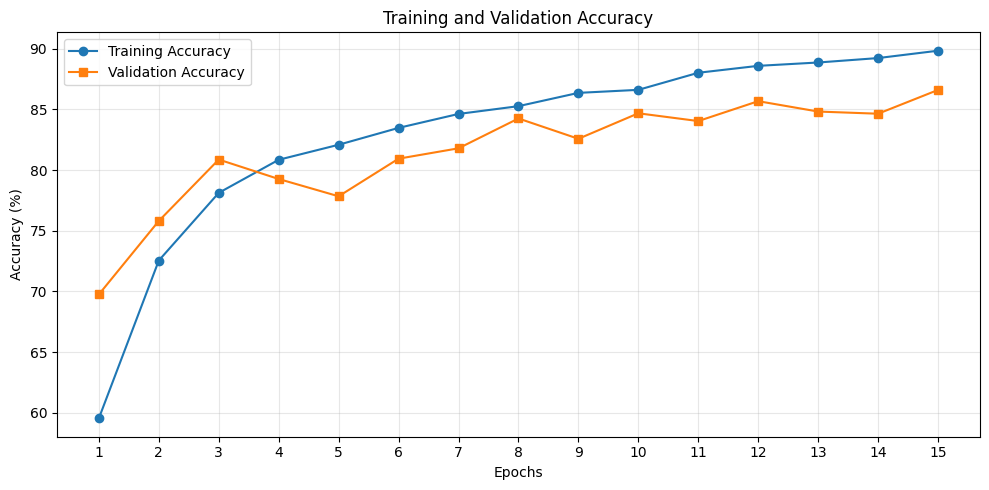

In [19]:

# Step 19: Plot Training and Validation Accuracy

epochs_range = range(1, len(history["train_accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(epochs_range)
plt.tight_layout()
plt.show()


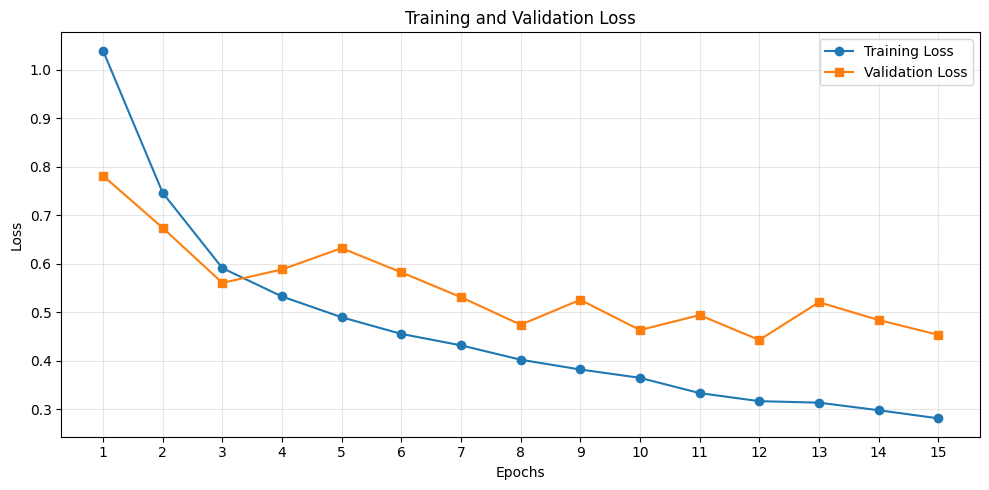

In [20]:

# Step 20: Plot Training and Validation Loss

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(epochs_range)
plt.tight_layout()
plt.show()


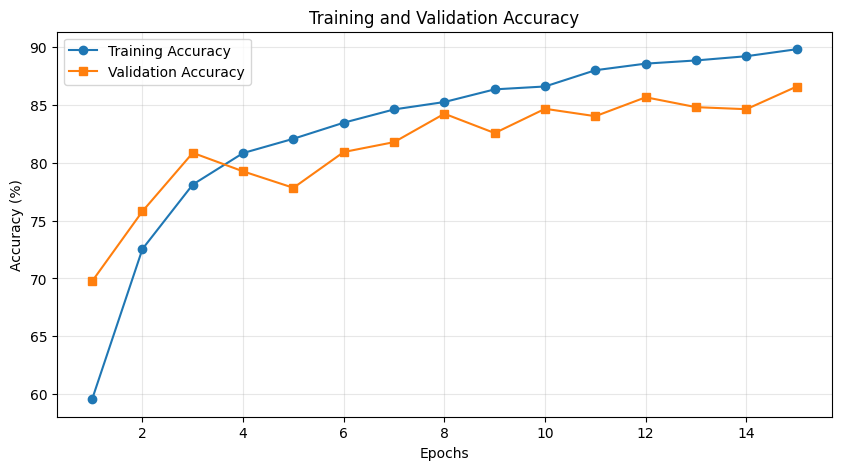

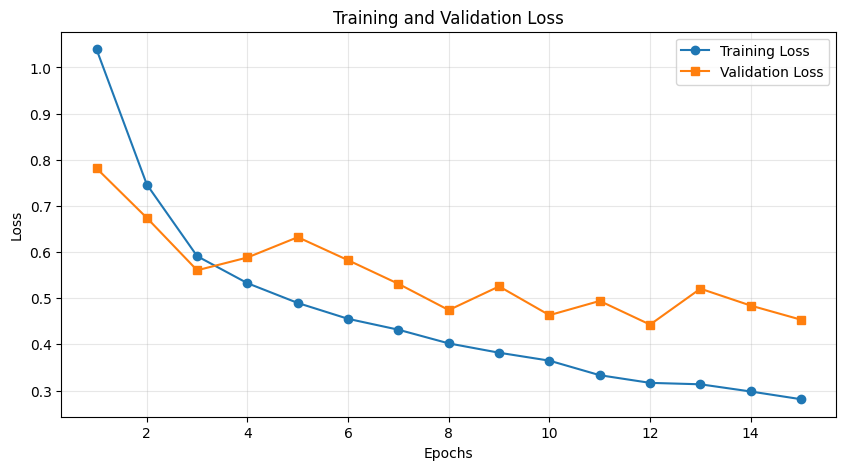

Both graphs saved successfully!


In [21]:

# Step 21: Save accuracy and loss graphs

# Save accuracy graph
plt.figure(figsize=(10, 5))

plt.plot(epochs_range, history["train_accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(epochs_range, history["val_accuracy"],
         marker="s", label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig("/content/accuracy_curve.png",
            dpi=300, bbox_inches="tight")

plt.show()


# Save loss graph
plt.figure(figsize=(10, 5))

plt.plot(epochs_range, history["train_loss"],
         marker="o", label="Training Loss")

plt.plot(epochs_range, history["val_loss"],
         marker="s", label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig("/content/loss_curve.png",
            dpi=300, bbox_inches="tight")

plt.show()

print("Both graphs saved successfully!")


### Analysis of Training and Validation Curves

The training accuracy increased from 59.54% in the first epoch to 89.84% in the final epoch. The validation accuracy also improved and reached 86.60% in the final epoch.

The training loss generally decreased throughout the training process. The lowest validation loss was 0.4428 at epoch 12.

There were some fluctuations in validation loss and accuracy during training. However, the model showed good learning performance. The small difference between final training and validation accuracy suggests that the model generalizes reasonably well to unseen validation images.

In [22]:
# Load the best model saved during training
model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

model.to(device)
model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [23]:
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Test predictions completed!")

Test predictions completed!


In [24]:
from sklearn.metrics import accuracy_score, classification_report

test_accuracy = accuracy_score(all_labels, all_preds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        digits=4
    )
)

Test Accuracy: 86.00%

Classification Report:
              precision    recall  f1-score   support

   buildings     0.7907    0.8902    0.8375       437
      forest     0.9465    0.9705    0.9583       474
     glacier     0.8755    0.7631    0.8155       553
    mountain     0.8102    0.8210    0.8155       525
         sea     0.8487    0.9020    0.8745       510
      street     0.8970    0.8343    0.8645       501

    accuracy                         0.8600      3000
   macro avg     0.8614    0.8635    0.8610      3000
weighted avg     0.8620    0.8600    0.8595      3000



Best-performing class: Forest, with a 95.83% F1-score.



Weakest class: Glacier, with an 81.55% F1-score.



Overall: Macro F1-score is 86.10%, showing fairly balanced performance across the six classes.

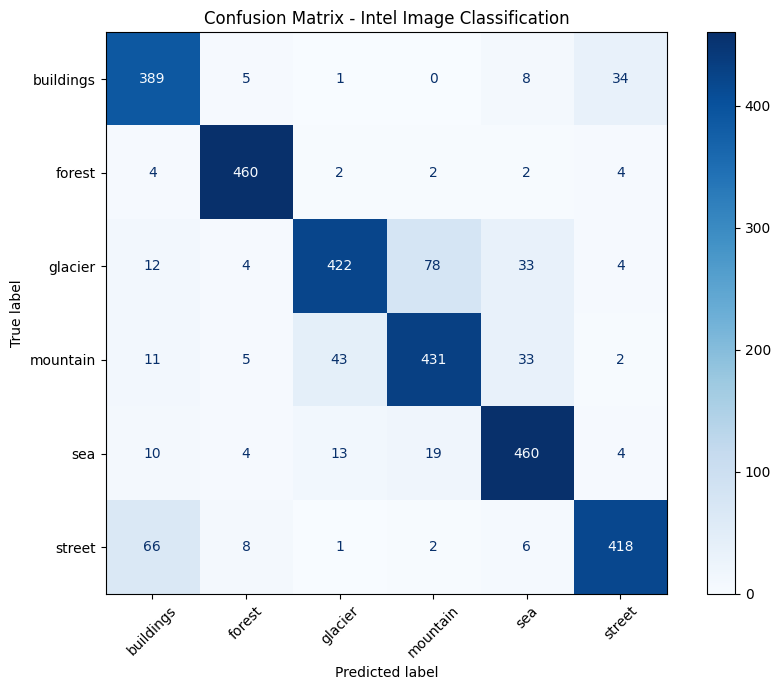

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap="Blues", values_format="d", ax=ax)

plt.title("Confusion Matrix - Intel Image Classification")
plt.xticks(rotation=45)
plt.tight_layout()

# Save the figure
plt.savefig("/content/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Analysis and Discussion

The CNN model achieved 86.00% accuracy on the test dataset containing 3,000 images. The training accuracy reached 89.84%, while the validation accuracy reached 86.60%.

The forest class achieved the best performance, with an F1-score of 95.83%. The model was also able to classify sea and street images with good accuracy.

However, the glacier class was more challenging, with an F1-score of 81.55%. The confusion matrix shows that 78 glacier images were incorrectly classified as mountains. Similarly, 66 street images were classified as buildings.

These mistakes may happen because some classes have similar visual features. For example, glaciers and mountains can have similar snowy landscapes, while buildings and streets may appear together in urban images.

Overall, the model learned useful image features and achieved good classification performance. However, there is still room for improvement.



## 9. Conclusion and Future Work

In this project, I developed a custom Convolutional Neural Network (CNN) using PyTorch to classify images from the Intel Image Classification dataset. The model was trained to recognize six categories: buildings, forest, glacier, mountain, sea, and street.

The model achieved 86.00% test accuracy. The results show that a custom CNN can successfully learn visual features and classify different types of natural and urban scenes.

In the future, the model could be improved by using more training images, applying better data augmentation, tuning hyperparameters, and experimenting with deeper CNN architectures. Transfer learning with pretrained models could also help improve classification accuracy.


In [26]:
# Save the best trained model
final_model_path = "/content/final_cnn_model.pth"

torch.save(model.state_dict(), final_model_path)

print("Final model saved successfully!")

Final model saved successfully!


In [27]:
import os

file_size = os.path.getsize(final_model_path) / (1024 * 1024)

print(f"Model file size: {file_size:.2f} MB")

Model file size: 40.87 MB


In [28]:
from google.colab import files

files.download("/content/final_cnn_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>